# Perfil de luminosdiad de una galaxia

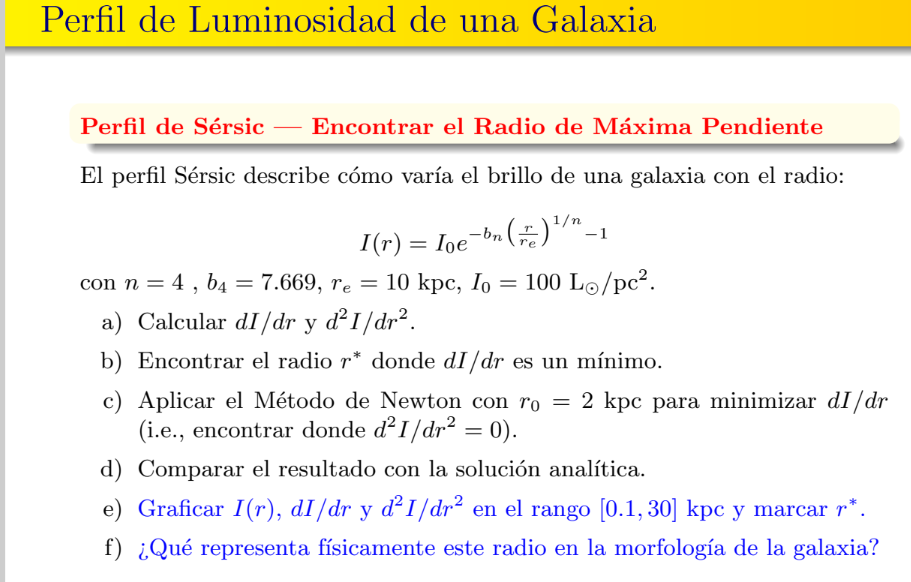

## a) Calcular $dI/dr$ y $d^2I/dr$

  $$I(r) = I_0 e^{-b_n \left(\frac{r}{r_e}\right)^{\frac{1}{n}} - 1}$$

 $$dI/dr = -\frac{I_0 b_n}{n r_e} \left(\frac{r}{r_e}\right)^{\frac{1-n}{n}} e^{-b_n \left(\frac{r}{r_e}\right)^{\frac{1}{n}} - 1}$$

  $$d^2I/dr^2 = \frac{I_0 b_n}{n^2 r_e^2} \left(\frac{r}{r_e}\right)^{\frac{1-2n}{n}} \left[ b_n \left(\frac{r}{r_e}\right)^{\frac{1}{n}} + n - 1 \right] e^{-b_n \left(\frac{r}{r_e}\right)^{\frac{1}{n}} - 1}$$

## b) Encontrar el radio r donde $dI/dr$ es un minimo

$$\frac{I_0 b_n}{n^2 r_e^2} \left(\frac{r}{r_e}\right)^{\frac{1-2n}{n}} \left[ b_n \left(\frac{r}{r_e}\right)^{\frac{1}{n}} + n - 1 \right] e^{-b_n \left(\frac{r}{r_e}\right)^{\frac{1}{n}} - 1} = 0$$

Dado que las constantes y los términos exponenciales son siempre positivos para cualquier radio $r > 0$, la única forma de que toda la ecuación sea cero es que el término dentro de los corchetes sea cero:$$b_n \left(\frac{r}{r_e}\right)^{\frac{1}{n}} + n - 1 = 0$$

$$b_n \left(\frac{r}{r_e}\right)^{\frac{1}{n}} = 1 - n$$$$\left(\frac{r}{r_e}\right)^{\frac{1}{n}} = \frac{1 - n}{b_n}$$
$$\frac{r^*}{r_e} = \left( \frac{1 - n}{b_n} \right)^n$$$$r^* = r_e \left( \frac{1 - n}{b_n} \right)^n$$
Utilizando los valores dados en el problema ($n = 4$, $b_4 = 7.669$ y $r_e = 10$ kpc):
   $$r^* = 10 \left( \frac{1 - 4}{7.669} \right)^4$$ $$r^* = 10 \left( \frac{-3}{7.669} \right)^4$$ $$r^* = 10 (-0.39118)^4 \approx 10 (0.0234)$$$$r^* \approx 0.234 \text{ kpc}$$

## c) Encontrar numericamente el minimo de $dI/dr$

Para esto vamos a implementar la tercera derivada $d^3I/dr^3$

$$\frac{d^3I}{dr^3} = -\frac{I_0 b_n}{n^3 r_e^3} \left(\frac{r}{r_e}\right)^{\frac{1-3n}{n}} \left[ b_n^2 \left(\frac{r}{r_e}\right)^{\frac{2}{n}} + 3b_n(n-1) \left(\frac{r}{r_e}\right)^{\frac{1}{n}} + (n-1)(2n-1) \right] e^{-b_n \left(\frac{r}{r_e}\right)^{\frac{1}{n}} - 1}$$

In [5]:
import numpy as np
import matplotlib.pyplot as plt

In [8]:
def I_func(r):
    b = 7.669
    n = 4
    re = 10
    I0 = 100
    exponente = -b * (r / re)**(1 / n) - 1
    return I0 * np.exp(exponente)

def devI(r):
    b = 7.669
    n = 4
    re = 10
    I0 = 100
    exponente = -b * (r / re)**(1 / n) - 1
    coeficiente = -(I0 * b) / (n * re)
    termino_r = (r / re)**((1 - n) / n)
    
    return coeficiente * termino_r * np.exp(exponente)

def devI2(r):
    b = 7.669
    n = 4
    re = 10
    I0 = 100

    exponente = -b * (r / re)**(1 / n) - 1
    coeficiente = (I0 * b) / (n**2 * re**2)
    termino_r = (r / re)**((1 - 2 * n) / n)
    factor_interno = b * (r / re)**(1 / n) + n - 1

    return coeficiente * termino_r * factor_interno * np.exp(exponente)

def devI3(r):
    b = 7.669
    n = 4
    re = 10
    I0 = 100
    
    exponente = -b * (r / re)**(1 / n) - 1
    coeficiente = -(I0 * b) / (n**3 * re**3)
    termino_r = (r / re)**((1 - 3 * n) / n)
    
    factor_interno = (b**2 * (r / re)**(2 / n) + 
                      3 * b * (n - 1) * (r / re)**(1 / n) + 
                      (n - 1) * (2 * n - 1))
    
    return coeficiente * termino_r * factor_interno * np.exp(exponente)

#Algoritmo de Newton

r_i = 2.0
eps =0.05
iteracion = 0
error_rel = 1.0
val_deriv = devI2(r_i)


while np.abs(val_deriv) >= eps and error_rel >= eps:
    iteracion = iteracion + 1
    deriv = devI2(r_i)
    dderiv = devI3(r_i)
    r_i_next = r_i - deriv/dderiv
    error_rel = np.abs((r_i_next - r_i)/ r_i_next)
    val_deriv = devI2(r_i_next)
    r_i = r_i_next
    print ("Iteracion:", iteracion, "valor de r:", r_i)
print(r_i, "es el radio donde dI/dr es un minimo")


Iteracion: 1 valor de r: 2.695795082216975
Iteracion: 2 valor de r: 3.6036337490029804
3.6036337490029804 es el radio donde dI/dr es un minimo


## d) Comparar el resultado con la solucion analitica

se puede apreciar una diferencia seria entre la solucion analitica y la numerica, seguramente debido a que el límite de tolerancia (eps) se alcanzó prematuramente (la segunda derivada devI2 es menor a eps = 0.05). A medida que el radio $r$ crece, la curva de la segunda derivada se aplana y se acerca a cero sin llegar a tocarlo. En la iteración 2 ($r \approx 3.60$), el valor de devI2(3.60) se hace tan pequeño (menor a $0.05$) que el programa asume erróneamente que ya encontró la raíz y se detiene.

Adicionalmente, La raíz analítica (0.234) es un "falso positivo" matemático, para que $d^2I/dr^2 = 0$, el término interno debe ser cero:$7.669 \left(\frac{r}{10}\right)^{0.25} + 3 = 0$
Dado que $r$ debe ser un número positivo (el radio de una galaxia no puede ser negativo), ese término es siempre positivo y jamás será igual a cero.

## e) graficar I(r), $dI/dr$, $d^2I/dr^2$

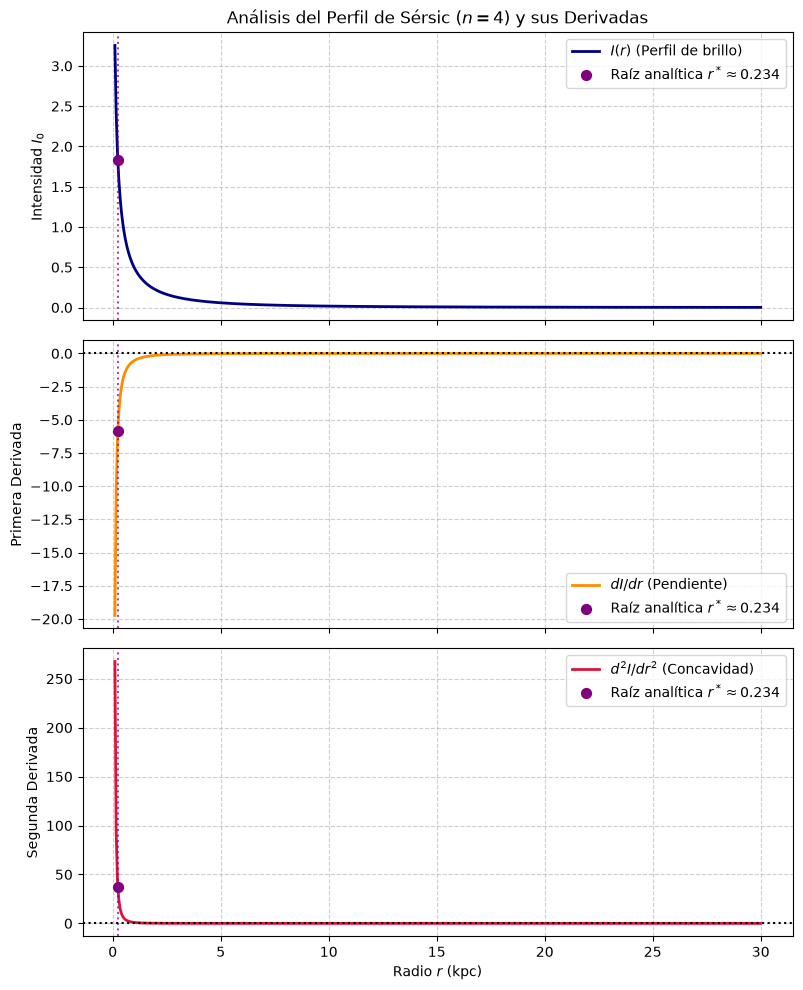

In [23]:
#Lista de puntos 
radios = np.linspace(0.1, 30.0, 500)

#Graficas

r_star = 0.234

fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(8, 10), sharex=True)

# 1. Gráfica de la función original I(r)
ax1.plot(radios, I_func(radios), color='navy', linewidth=2, label='$I(r)$ (Perfil de brillo)')
ax1.scatter(r_star, I_func(r_star), color='purple', zorder=5, s=50, label=f'Raíz analítica $r^* \\approx {r_star}$') # Punto
ax1.axvline(r_star, color='purple', linestyle=':', alpha=0.7) # Línea vertical
ax1.set_ylabel('Intensidad $I_0$')
ax1.set_title('Análisis del Perfil de Sérsic ($n=4$) y sus Derivadas')
ax1.grid(True, linestyle='--', alpha=0.6)
ax1.legend()

# 2. Gráfica de la primera derivada dI/dr
ax2.plot(radios, devI(radios), color='darkorange', linewidth=2, label='$dI/dr$ (Pendiente)')
ax2.scatter(r_star, devI(r_star), color='purple', zorder=5, s=50, label=f'Raíz analítica $r^* \\approx {r_star}$')
ax2.axvline(r_star, color='purple', linestyle=':', alpha=0.7)
ax2.axhline(0, color='black', linestyle=':', linewidth=1.5)
ax2.set_ylabel('Primera Derivada')
ax2.grid(True, linestyle='--', alpha=0.6)
ax2.legend()

# 3. Gráfica de la segunda derivada d^2I/dr^2
ax3.plot(radios, devI2(radios), color='crimson', linewidth=2, label='$d^2I/dr^2$ (Concavidad)')
ax3.scatter(r_star, devI2(r_star), color='purple', zorder=5, s=50, label=f'Raíz analítica $r^* \\approx {r_star}$')
ax3.axvline(r_star, color='purple', linestyle=':', alpha=0.7)
ax3.axhline(0, color='black', linestyle=':', linewidth=1.5)
ax3.set_xlabel('Radio $r$ (kpc)')
ax3.set_ylabel('Segunda Derivada')
ax3.grid(True, linestyle='--', alpha=0.6)
ax3.legend()

plt.tight_layout()
plt.show()

## f) Que representa fisicamente este radio en la morfologia de la galaxia=

el punto donde la primera derivada ($dI/dr$) alcanza su mínimo absoluto representa la región donde el brillo de la galaxia cae con la mayor brusquedad, tambien tenemos que el brillo disminuye continuamente y la curva se va aplanando (es estrictamente convexa) a medida que te alejas del centro. No hay ninguna caída súbita de luz en sus afueras; la galaxia simplemente se difumina gradualmente en el espacio intergaláctico.